In [1]:
# ============================================================
# TELECOMMUNICATION CUSTOMER CHURN PREDICTION
# USING EXPLAINABLE MACHINE LEARNING
# ============================================================

# Data manipulation
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Warnings
import warnings
warnings.filterwarnings("ignore")

# Display
from IPython.display import display

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# ============================================================
# LOAD DATASET
# ============================================================

from google.colab import files

uploaded = files.upload()

# Find CSV file
csv_files = [
    filename for filename in uploaded.keys()
    if filename.lower().endswith(".csv")
]

if len(csv_files) == 0:
    raise ValueError("Please upload a CSV dataset.")

file_name = csv_files[0]

# Load dataset
df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("File:", file_name)
print("Shape:", df.shape)

display(df.head())

Saving customer_churn dataset.csv to customer_churn dataset.csv
Dataset loaded successfully!
File: customer_churn dataset.csv
Shape: (3333, 20)


,State,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls,Churn
0,LA,117,408,No,No,0,184.5,97,31.37,351.6,80,29.89,215.8,90,9.71,8.7,4,2.35,1,False
1,IN,65,415,No,No,0,129.1,137,21.95,228.5,83,19.42,208.8,111,9.40,12.7,6,3.43,4,True
2,NY,161,415,No,No,0,332.9,67,56.59,317.8,97,27.01,160.6,128,7.23,5.4,9,1.46,4,True
3,SC,111,415,No,No,0,110.4,103,18.77,137.3,102,11.67,189.6,105,8.53,7.7,6,2.08,2,False
4,HI,49,510,No,No,0,119.3,117,20.28,215.1,109,18.28,178.7,90,8.04,11.1,1,3.00,1,False


In [3]:
# ============================================================
# DATASET OVERVIEW
# ============================================================

print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nDataset Information:")
df.info()

Dataset Shape:
(3333, 20)

Column Names:
['State', 'Account length', 'Area code', 'International plan', 'Voice mail plan', 'Number vmail messages', 'Total day minutes', 'Total day calls', 'Total day charge', 'Total eve minutes', 'Total eve calls', 'Total eve charge', 'Total night minutes', 'Total night calls', 'Total night charge', 'Total intl minutes', 'Total intl calls', 'Total intl charge', 'Customer service calls', 'Churn']

Data Types:
State                      object
Account length              int64
Area code                   int64
International plan         object
Voice mail plan            object
Number vmail messages       int64
Total day minutes         float64
Total day calls             int64
Total day charge          float64
Total eve minutes         float64
Total eve calls             int64
Total eve charge          float64
Total night minutes       float64
Total night calls           int64
Total night charge        float64
Total intl minutes        float64
Total intl 

In [4]:
# ============================================================
# DATA QUALITY CHECK
# ============================================================

print("Missing Values:")
display(
    df.isnull()
      .sum()
      .sort_values(ascending=False)
      .to_frame("Missing Values")
)

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Missing Values:


,Missing Values
State,0
Account length,0
Area code,0
International plan,0
Voice mail plan,0
Number vmail messages,0
Total day minutes,0
Total day calls,0
Total day charge,0
Total eve minutes,0



Total Missing Values:
0

Duplicate Rows:
0


In [5]:
# ============================================================
# REMOVE DUPLICATES
# ============================================================

duplicate_count = df.duplicated().sum()

if duplicate_count > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    print(f"{duplicate_count} duplicate rows removed.")
else:
    print("No duplicate rows found.")

print("Updated dataset shape:", df.shape)

No duplicate rows found.
Updated dataset shape: (3333, 20)


In [6]:
# ============================================================
# TARGET VARIABLE
# ============================================================

TARGET = "Churn"

if TARGET not in df.columns:
    raise ValueError(
        f"Target column '{TARGET}' was not found."
    )

print("Target variable:", TARGET)

print("\nTarget values:")
print(df[TARGET].value_counts(dropna=False))

Target variable: Churn

Target values:
Churn
False    2850
True      483
Name: count, dtype: int64


In [7]:
# ============================================================
# TARGET ENCODING
# ============================================================

# Remove rows where target is missing
df = df.dropna(subset=[TARGET]).copy()

# Convert True/False or Yes/No to 0/1
if df[TARGET].dtype == bool:
    df[TARGET] = df[TARGET].astype(int)

elif df[TARGET].dtype == object:

    target_values = (
        df[TARGET]
        .astype(str)
        .str.strip()
        .str.lower()
    )

    target_mapping = {
        "true": 1,
        "false": 0,
        "yes": 1,
        "no": 0,
        "1": 1,
        "0": 0,
        "churn": 1,
        "no churn": 0,
        "churned": 1,
        "stayed": 0
    }

    mapped = target_values.map(target_mapping)

    if mapped.isnull().any():
        unique_values = target_values.unique()

        if len(unique_values) == 2:
            mapping = {
                unique_values[0]: 0,
                unique_values[1]: 1
            }

            print("Automatic target mapping:")
            print(mapping)

            mapped = target_values.map(mapping)

        else:
            raise ValueError(
                f"Unexpected target values: {unique_values}"
            )

    df[TARGET] = mapped.astype(int)

else:
    df[TARGET] = df[TARGET].astype(int)

print("Final target values:")
print(df[TARGET].value_counts())

print("\nTarget distribution:")
display(
    df[TARGET]
    .value_counts()
    .rename(index={
        0: "Stayed",
        1: "Churned"
    })
    .to_frame("Number of Customers")
)

Final target values:
Churn
0    2850
1     483
Name: count, dtype: int64

Target distribution:


,Number of Customers
Churn,
Stayed,2850
Churned,483


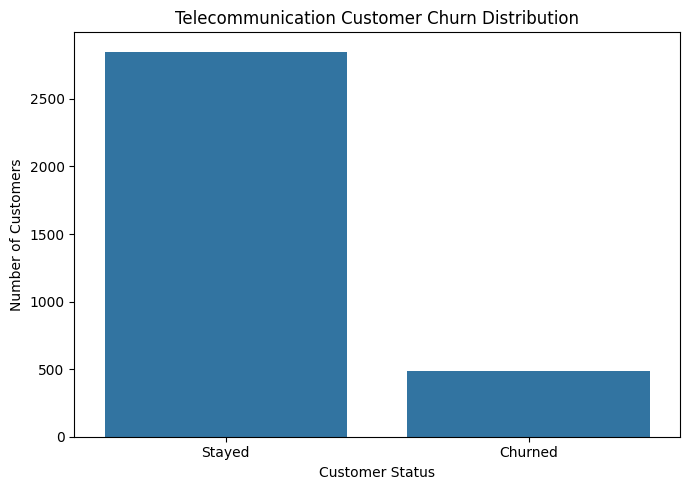

Churn Percentage:
Stayed  : 85.51%
Churned : 14.49%


In [8]:
# ============================================================
# CHURN DISTRIBUTION
# ============================================================

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x=TARGET
)

plt.title(
    "Telecommunication Customer Churn Distribution"
)

plt.xlabel("Customer Status")
plt.ylabel("Number of Customers")

plt.xticks(
    [0, 1],
    ["Stayed", "Churned"]
)

plt.tight_layout()
plt.show()

# Percentages
print("Churn Percentage:")

percentage = (
    df[TARGET]
    .value_counts(normalize=True)
    .sort_index() * 100
)

print(f"Stayed  : {percentage[0]:.2f}%")
print(f"Churned : {percentage[1]:.2f}%")

In [9]:
# ============================================================
# STATISTICAL SUMMARY
# ============================================================

display(
    df.describe(include="all").T
)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
State,3333,51,WV,106,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Account length,3333.0,NaN,NaN,NaN,101.064806,39.822106,1.0,74.0,101.0,127.0,243.0
Area code,3333.0,NaN,NaN,NaN,437.182418,42.37129,408.0,408.0,415.0,510.0,510.0
International plan,3333,2,No,3010,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Voice mail plan,3333,2,No,2411,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Number vmail messages,3333.0,NaN,NaN,NaN,8.09901,13.688365,0.0,0.0,0.0,20.0,51.0
Total day minutes,3333.0,NaN,NaN,NaN,179.775098,54.467389,0.0,143.7,179.4,216.4,350.8
Total day calls,3333.0,NaN,NaN,NaN,100.435644,20.069084,0.0,87.0,101.0,114.0,165.0
Total day charge,3333.0,NaN,NaN,NaN,30.562307,9.259435,0.0,24.43,30.5,36.79,59.64
Total eve minutes,3333.0,NaN,NaN,NaN,200.980348,50.713844,0.0,166.6,201.4,235.3,363.7


In [10]:
# ============================================================
# NUMERICAL FEATURES
# ============================================================

numeric_columns = df.select_dtypes(
    include=np.number
).columns.tolist()

print("Numerical columns:")
print(numeric_columns)

print("\nNumber of numerical features:")
print(len(numeric_columns))

Numerical columns:
['Account length', 'Area code', 'Number vmail messages', 'Total day minutes', 'Total day calls', 'Total day charge', 'Total eve minutes', 'Total eve calls', 'Total eve charge', 'Total night minutes', 'Total night calls', 'Total night charge', 'Total intl minutes', 'Total intl calls', 'Total intl charge', 'Customer service calls', 'Churn']

Number of numerical features:
17


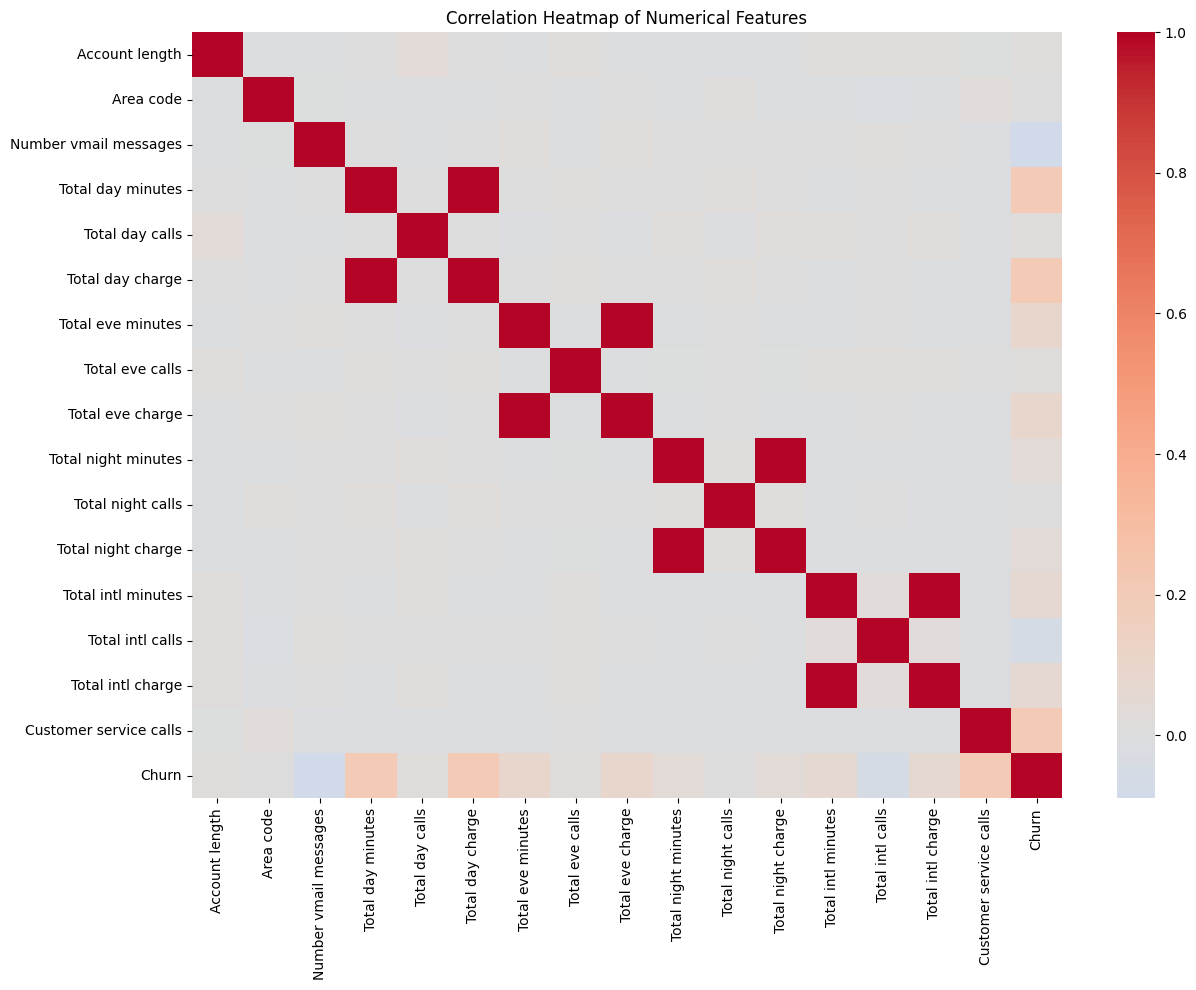

In [11]:
# ============================================================
# CORRELATION ANALYSIS
# ============================================================

correlation_matrix = df[numeric_columns].corr()

plt.figure(figsize=(13, 10))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    annot=False
)

plt.title(
    "Correlation Heatmap of Numerical Features"
)

plt.tight_layout()
plt.show()

Churn percentage by International Plan:


Churn,0,1
International plan,,
No,88.50,11.50
Yes,57.59,42.41


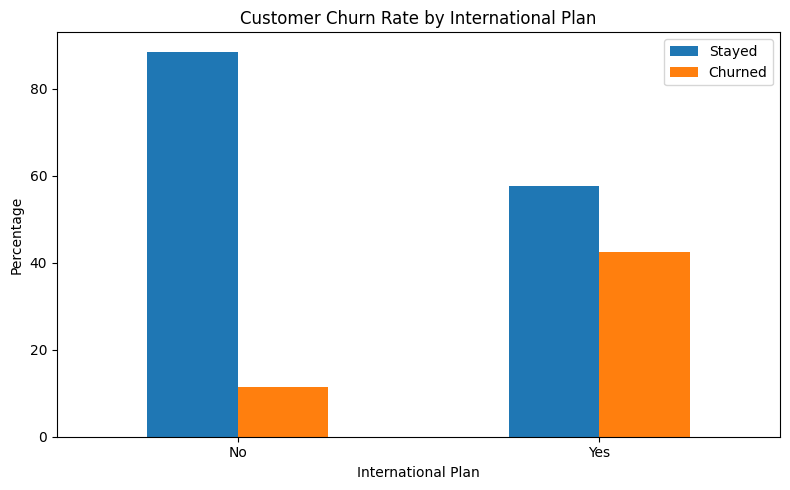

In [12]:
# ============================================================
# INTERNATIONAL PLAN VS CHURN
# ============================================================

if "International plan" in df.columns:

    churn_plan = pd.crosstab(
        df["International plan"],
        df[TARGET],
        normalize="index"
    ) * 100

    print("Churn percentage by International Plan:")
    display(churn_plan.round(2))

    churn_plan.plot(
        kind="bar",
        figsize=(8, 5)
    )

    plt.title(
        "Customer Churn Rate by International Plan"
    )

    plt.xlabel("International Plan")
    plt.ylabel("Percentage")

    plt.xticks(rotation=0)

    plt.legend(
        ["Stayed", "Churned"]
    )

    plt.tight_layout()
    plt.show()

Churn percentage by Customer Service Calls:


Churn,0,1
Customer service calls,,
0,86.80,13.20
1,89.67,10.33
2,88.54,11.46
3,89.74,10.26
4,54.22,45.78
5,39.39,60.61
6,36.36,63.64
7,44.44,55.56
8,50.00,50.00


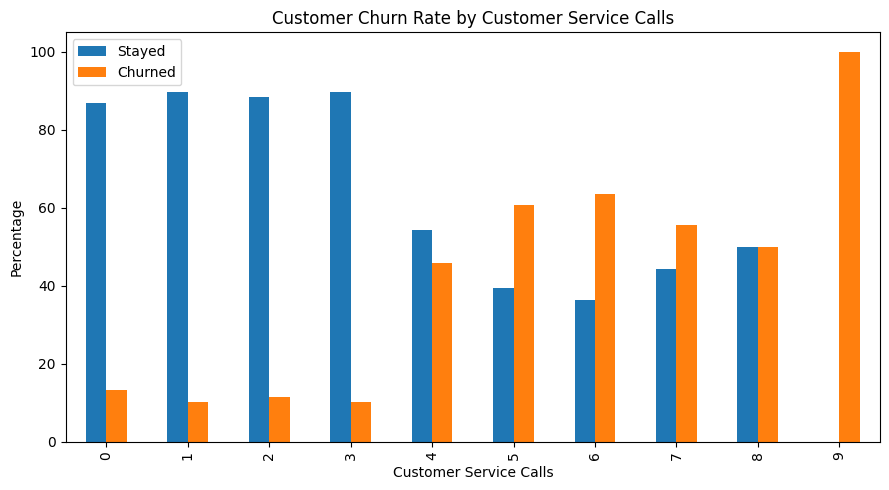

In [13]:
# ============================================================
# CUSTOMER SERVICE CALLS VS CHURN
# ============================================================

if "Customer service calls" in df.columns:

    service_churn = pd.crosstab(
        df["Customer service calls"],
        df[TARGET],
        normalize="index"
    ) * 100

    print(
        "Churn percentage by Customer Service Calls:"
    )

    display(
        service_churn.round(2)
    )

    service_churn.plot(
        kind="bar",
        figsize=(9, 5)
    )

    plt.title(
        "Customer Churn Rate by Customer Service Calls"
    )

    plt.xlabel(
        "Customer Service Calls"
    )

    plt.ylabel(
        "Percentage"
    )

    plt.legend(
        ["Stayed", "Churned"]
    )

    plt.tight_layout()
    plt.show()

In [14]:
# ============================================================
# FEATURES AND TARGET
# ============================================================

X = df.drop(
    columns=[TARGET]
).copy()

y = df[TARGET].copy()

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (3333, 19)
Target shape: (3333,)


In [15]:
# ============================================================
# REMOVE ID-LIKE AND CONSTANT FEATURES
# ============================================================

# Possible ID columns
id_like_columns = [
    column for column in X.columns
    if column.lower().strip() in [
        "id",
        "customer id",
        "customer_id",
        "customerid"
    ]
]

if id_like_columns:

    print(
        "Removing ID-like columns:",
        id_like_columns
    )

    X = X.drop(
        columns=id_like_columns
    )

# Constant columns
constant_columns = [
    column for column in X.columns
    if X[column].nunique(dropna=False) <= 1
]

if constant_columns:

    print(
        "Removing constant columns:",
        constant_columns
    )

    X = X.drop(
        columns=constant_columns
    )

print("\nFinal features:")
print(X.columns.tolist())

print("\nFinal feature count:", X.shape[1])


Final features:
['State', 'Account length', 'Area code', 'International plan', 'Voice mail plan', 'Number vmail messages', 'Total day minutes', 'Total day calls', 'Total day charge', 'Total eve minutes', 'Total eve calls', 'Total eve charge', 'Total night minutes', 'Total night calls', 'Total night charge', 'Total intl minutes', 'Total intl calls', 'Total intl charge', 'Customer service calls']

Final feature count: 19


In [16]:
# ============================================================
# TRAIN / VALIDATION / TEST SPLIT
# ============================================================

from sklearn.model_selection import train_test_split

# 70% Training
# 30% Temporary

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# 15% Validation
# 15% Testing

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Testing set:", X_test.shape)

print("\nChurn rate:")
print(
    f"Training   : {y_train.mean():.4f}"
)

print(
    f"Validation : {y_val.mean():.4f}"
)

print(
    f"Testing    : {y_test.mean():.4f}"
)

Training set: (2333, 19)
Validation set: (500, 19)
Testing set: (500, 19)

Churn rate:
Training   : 0.1449
Validation : 0.1460
Testing    : 0.1440


In [17]:
# ============================================================
# IDENTIFY CATEGORICAL AND NUMERICAL FEATURES
# ============================================================

categorical_features = X_train.select_dtypes(
    include=[
        "object",
        "category",
        "bool",
        "string"
    ]
).columns.tolist()

numerical_features = [
    column for column in X_train.columns
    if column not in categorical_features
]

print("Categorical Features:")
print(categorical_features)

print("\nNumerical Features:")
print(numerical_features)

Categorical Features:
['State', 'International plan', 'Voice mail plan']

Numerical Features:
['Account length', 'Area code', 'Number vmail messages', 'Total day minutes', 'Total day calls', 'Total day charge', 'Total eve minutes', 'Total eve calls', 'Total eve charge', 'Total night minutes', 'Total night calls', 'Total night charge', 'Total intl minutes', 'Total intl calls', 'Total intl charge', 'Customer service calls']


In [18]:
# ============================================================
# PREPROCESSING PIPELINE
# ============================================================

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)
from sklearn.impute import SimpleImputer

# Numerical preprocessing
numeric_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

# Categorical preprocessing
categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer,
            numerical_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

print(
    "Professional preprocessing pipeline created!"
)

Professional preprocessing pipeline created!


In [26]:
# ============================================================
# MACHINE LEARNING MODELS
# ============================================================

from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import (
    RandomForestClassifier,
    HistGradientBoostingClassifier
)

print("Three classification models selected:")
print("1. Logistic Regression")
print("2. Random Forest")
print("3. Histogram Gradient Boosting")

Three classification models selected:
1. Logistic Regression
2. Random Forest
3. Histogram Gradient Boosting


In [33]:
# ============================================================
# CREATE MACHINE LEARNING MODELS
# ============================================================

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    HistGradientBoostingClassifier
)

# ------------------------------------------------------------
# IMPORTANT:
# HistGradientBoosting requires dense input.
# Therefore, we use a separate preprocessing pipeline
# with dense OneHotEncoder for this model.
# ------------------------------------------------------------

# Preprocessor for Logistic Regression and Random Forest
preprocessor_sparse = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer,
            numerical_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

# Dense categorical preprocessing for HistGradientBoosting
categorical_transformer_dense = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="most_frequent"
            )
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ]
)

preprocessor_dense = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer,
            numerical_features
        ),
        (
            "cat",
            categorical_transformer_dense,
            categorical_features
        )
    ]
)

# ------------------------------------------------------------
# MODELS
# ------------------------------------------------------------

models = {

    "Logistic Regression":
        Pipeline(
            steps=[
                (
                    "preprocessor",
                    preprocessor_sparse
                ),
                (
                    "model",
                    LogisticRegression(
                        max_iter=2000,
                        class_weight="balanced",
                        random_state=42
                    )
                )
            ]
        ),

    "Random Forest":
        Pipeline(
            steps=[
                (
                    "preprocessor",
                    preprocessor_sparse
                ),
                (
                    "model",
                    RandomForestClassifier(
                        n_estimators=300,
                        class_weight="balanced",
                        random_state=42,
                        n_jobs=-1
                    )
                )
            ]
        ),

    "Histogram Gradient Boosting":
        Pipeline(
            steps=[
                (
                    "preprocessor",
                    preprocessor_dense
                ),
                (
                    "model",
                    HistGradientBoostingClassifier(
                        max_iter=150,
                        learning_rate=0.08,
                        random_state=42
                    )
                )
            ]
        )
    }

print("Models created successfully!")
print("1. Logistic Regression")
print("2. Random Forest")
print("3. Histogram Gradient Boosting")

Models created successfully!
1. Logistic Regression
2. Random Forest
3. Histogram Gradient Boosting


In [30]:
# ============================================================
# CREATE BASE MODELS
# ============================================================

models = {

    "Logistic Regression":
        LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        ),

    "Random Forest":
        RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ),

    "Histogram Gradient Boosting":
        HistGradientBoostingClassifier(
            max_iter=150,
            learning_rate=0.08,
            random_state=42
        )
}

print("Models created successfully!")

Models created successfully!


In [34]:
# ============================================================
# TRAIN THREE MODELS
# ============================================================

fitted_models = {}

for model_name, pipeline in models.items():

    pipeline.fit(
        X_train,
        y_train
    )

    fitted_models[model_name] = pipeline

    print(
        f"{model_name} trained successfully!"
    )

print("\nAll models trained successfully!")

Logistic Regression trained successfully!
Random Forest trained successfully!
Histogram Gradient Boosting trained successfully!

All models trained successfully!


In [35]:
# ============================================================
# VALIDATION EVALUATION
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

validation_results = []

for model_name, model in fitted_models.items():

    predictions = model.predict(
        X_val
    )

    probabilities = model.predict_proba(
        X_val
    )[:, 1]

    validation_results.append({

        "Model": model_name,

        "Accuracy":
            accuracy_score(
                y_val,
                predictions
            ),

        "Precision":
            precision_score(
                y_val,
                predictions,
                zero_division=0
            ),

        "Recall":
            recall_score(
                y_val,
                predictions,
                zero_division=0
            ),

        "F1 Score":
            f1_score(
                y_val,
                predictions,
                zero_division=0
            ),

        "ROC-AUC":
            roc_auc_score(
                y_val,
                probabilities
            )
    })

validation_results_df = pd.DataFrame(
    validation_results
).sort_values(
    by="ROC-AUC",
    ascending=False
).reset_index(drop=True)

display(
    validation_results_df.round(4)
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Histogram Gradient Boosting,0.944,0.9245,0.6712,0.7778,0.8985
1,Random Forest,0.922,0.9250,0.5068,0.6549,0.8816
2,Logistic Regression,0.730,0.3133,0.7123,0.4351,0.7750


In [37]:
# ============================================================
# HYPERPARAMETER TUNING — RANDOM FOREST
# ============================================================

from sklearn.model_selection import GridSearchCV

rf_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            RandomForestClassifier(
                class_weight="balanced",
                random_state=42,
              n_jobs=-1
            )
        )
    ]
)

rf_param_grid = {

    "model__n_estimators": [
        200,
        300
    ],

    "model__max_depth": [
        None,
        10,
        15
    ],

    "model__min_samples_split": [
        2,
        5
    ],

    "model__min_samples_leaf": [
        1,
        2
    ]
}

rf_grid = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_param_grid,
    scoring="roc_auc",
    cv=3,
    n_jobs=-1,
    verbose=1
)

rf_grid.fit(
    X_train,
    y_train
)

print("\nBest Random Forest Parameters:")
print(rf_grid.best_params_)

print(
    "\nBest Cross-Validation ROC-AUC:",
    round(rf_grid.best_score_, 4)
)

Fitting 3 folds for each of 24 candidates, totalling 72 fits

Best Random Forest Parameters:
{'model__max_depth': 15, 'model__min_samples_leaf': 2, 'model__min_samples_split': 5, 'model__n_estimators': 200}

Best Cross-Validation ROC-AUC: 0.9159


In [38]:
# ============================================================
# EVALUATE TUNED RANDOM FOREST
# ============================================================

tuned_rf = rf_grid.best_estimator_

rf_val_pred = tuned_rf.predict(
    X_val
)

rf_val_prob = tuned_rf.predict_proba(
    X_val
)[:, 1]

tuned_rf_result = {

    "Model": "Tuned Random Forest",

    "Accuracy":
        accuracy_score(
            y_val,
            rf_val_pred
        ),

    "Precision":
        precision_score(
            y_val,
            rf_val_pred,
            zero_division=0
        ),

    "Recall":
        recall_score(
            y_val,
            rf_val_pred,
            zero_division=0
        ),

    "F1 Score":
        f1_score(
            y_val,
            rf_val_pred,
            zero_division=0
        ),

    "ROC-AUC":
        roc_auc_score(
            y_val,
            rf_val_prob
        )
}

validation_results_df = pd.concat(
    [
        validation_results_df,
        pd.DataFrame([tuned_rf_result])
    ],
    ignore_index=True
)

validation_results_df = validation_results_df.sort_values(
    by="ROC-AUC",
    ascending=False
).reset_index(drop=True)

display(
    validation_results_df.round(4)
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Histogram Gradient Boosting,0.944,0.9245,0.6712,0.7778,0.8985
1,Tuned Random Forest,0.928,0.7937,0.6849,0.7353,0.8882
2,Random Forest,0.922,0.9250,0.5068,0.6549,0.8816
3,Logistic Regression,0.730,0.3133,0.7123,0.4351,0.7750


In [39]:
# ============================================================
# SELECT BEST MODEL USING VALIDATION DATA ONLY
# ============================================================

best_model_name = (
    validation_results_df
    .iloc[0]["Model"]
)

if best_model_name == "Tuned Random Forest":

    best_model = tuned_rf

else:

    best_model = fitted_models[
        best_model_name
    ]

print("========================================")
print("BEST MODEL")
print("========================================")

print(
    "Selected Model:",
    best_model_name
)

print(
    "Validation ROC-AUC:",
    round(
        validation_results_df.iloc[0]["ROC-AUC"],
        4
    )
)

BEST MODEL
Selected Model: Histogram Gradient Boosting
Validation ROC-AUC: 0.8985


In [40]:
# ============================================================
# FINAL TEST EVALUATION
# ============================================================

from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

test_predictions = best_model.predict(
    X_test
)

test_probabilities = best_model.predict_proba(
    X_test
)[:, 1]

test_accuracy = accuracy_score(
    y_test,
    test_predictions
)

test_precision = precision_score(
    y_test,
    test_predictions,
    zero_division=0
)

test_recall = recall_score(
    y_test,
    test_predictions,
    zero_division=0
)

test_f1 = f1_score(
    y_test,
    test_predictions,
    zero_division=0
)

test_roc_auc = roc_auc_score(
    y_test,
    test_probabilities
)

print("========================================")
print("FINAL TEST RESULTS")
print("========================================")

print(
    f"Model     : {best_model_name}"
)

print(
    f"Accuracy  : {test_accuracy:.4f}"
)

print(
    f"Precision : {test_precision:.4f}"
)

print(
    f"Recall    : {test_recall:.4f}"
)

print(
    f"F1 Score  : {test_f1:.4f}"
)

print(
    f"ROC-AUC   : {test_roc_auc:.4f}"
)

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        test_predictions,
        target_names=[
            "Stayed",
            "Churned"
        ],
        zero_division=0
    )
)

FINAL TEST RESULTS
Model     : Histogram Gradient Boosting
Accuracy  : 0.9600
Precision : 0.9333
Recall    : 0.7778
F1 Score  : 0.8485
ROC-AUC   : 0.9197

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.96      0.99      0.98       428
     Churned       0.93      0.78      0.85        72

    accuracy                           0.96       500
   macro avg       0.95      0.88      0.91       500
weighted avg       0.96      0.96      0.96       500



<Figure size 700x600 with 0 Axes>

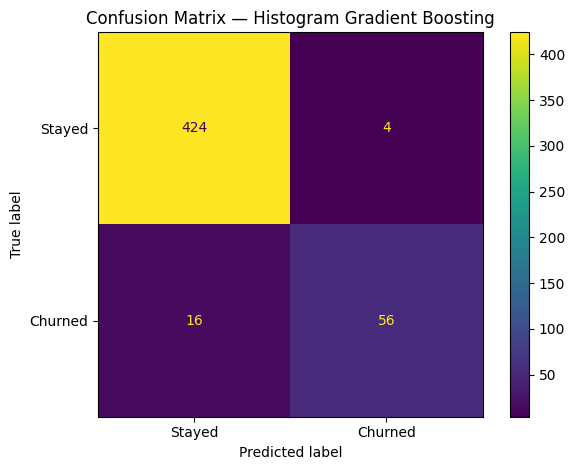

In [41]:
# ============================================================
# CONFUSION MATRIX
# ============================================================

from sklearn.metrics import ConfusionMatrixDisplay

plt.figure(figsize=(7, 6))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    display_labels=[
        "Stayed",
        "Churned"
    ]
)

plt.title(
    f"Confusion Matrix — {best_model_name}"
)

plt.tight_layout()
plt.show()

<Figure size 800x600 with 0 Axes>

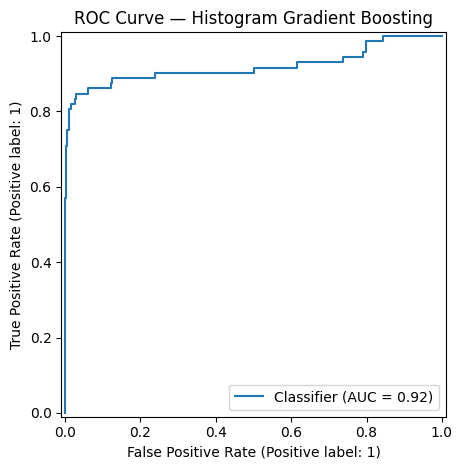

In [42]:
# ============================================================
# ROC CURVE
# ============================================================

from sklearn.metrics import RocCurveDisplay

plt.figure(figsize=(8, 6))

RocCurveDisplay.from_predictions(
    y_test,
    test_probabilities
)

plt.title(
    f"ROC Curve — {best_model_name}"
)

plt.tight_layout()
plt.show()

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Histogram Gradient Boosting,0.944,0.9245,0.6712,0.7778,0.8985
1,Tuned Random Forest,0.928,0.7937,0.6849,0.7353,0.8882
2,Random Forest,0.922,0.9250,0.5068,0.6549,0.8816
3,Logistic Regression,0.730,0.3133,0.7123,0.4351,0.7750


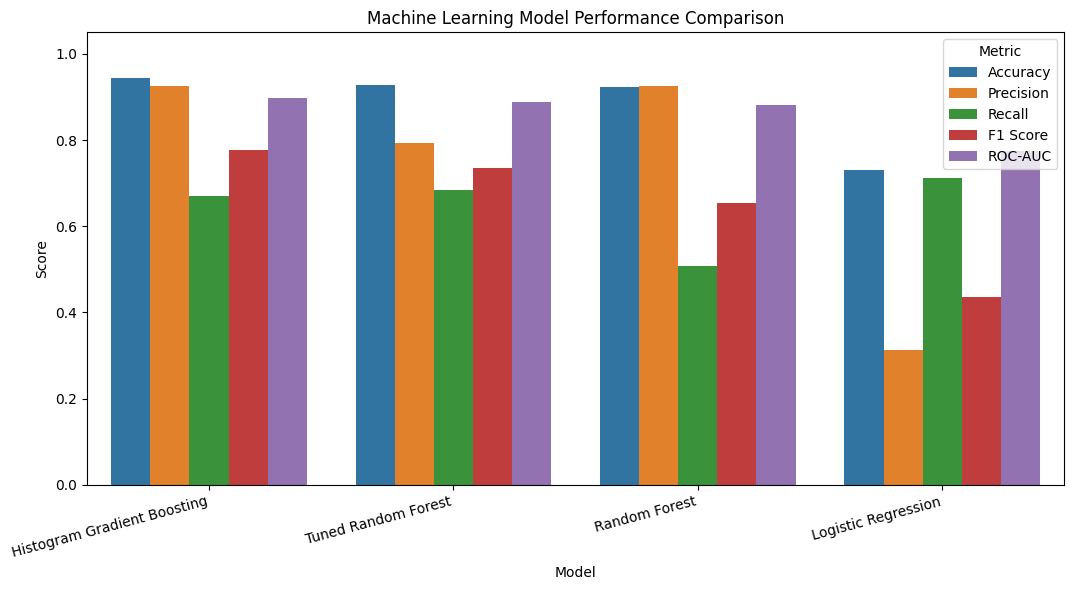

In [43]:
# ============================================================
# FINAL MODEL COMPARISON
# ============================================================

display(
    validation_results_df.round(4)
)

plt.figure(figsize=(11, 6))

comparison_plot = validation_results_df.melt(
    id_vars="Model",
    value_vars=[
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ],
    var_name="Metric",
    value_name="Score"
)

sns.barplot(
    data=comparison_plot,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.ylim(0, 1.05)

plt.title(
    "Machine Learning Model Performance Comparison"
)

plt.xlabel("Model")
plt.ylabel("Score")

plt.xticks(
    rotation=15,
    ha="right"
)

plt.tight_layout()
plt.show()

In [44]:
# ============================================================
# EXPLAINABLE MACHINE LEARNING
# PERMUTATION FEATURE IMPORTANCE
# ============================================================

from sklearn.inspection import permutation_importance

permutation = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({

    "Feature": X_test.columns,

    "Importance":
        permutation.importances_mean,

    "Std":
        permutation.importances_std

}).sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

print("Top 15 features influencing churn:")

display(
    importance_df.head(15).round(4)
)

Top 15 features influencing churn:


,Feature,Importance,Std
0,International plan,0.1480,0.0084
1,Total day minutes,0.1385,0.0150
2,Customer service calls,0.0856,0.0095
3,Total intl minutes,0.0555,0.0097
4,Total intl calls,0.0520,0.0097
5,Total eve minutes,0.0385,0.0100
6,Number vmail messages,0.0159,0.0053
7,Total night minutes,0.0072,0.0042
8,Total night calls,0.0047,0.0035
9,State,0.0034,0.0038


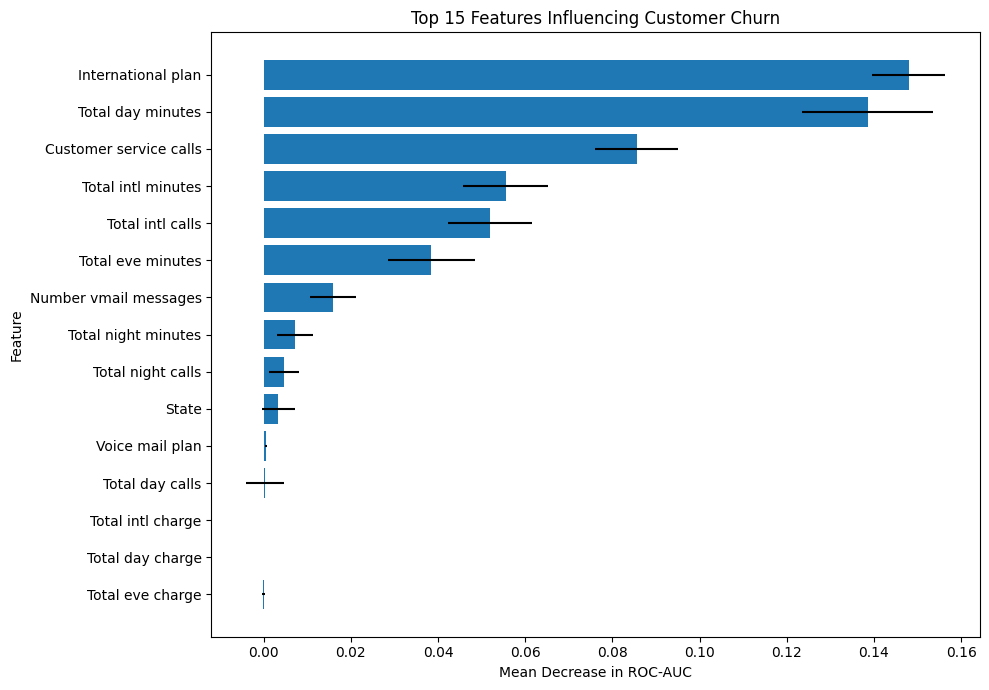

In [45]:
# ============================================================
# FEATURE IMPORTANCE VISUALIZATION
# ============================================================

top_features = (
    importance_df
    .head(15)
    .sort_values(
        by="Importance"
    )
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"],
    xerr=top_features["Std"]
)

plt.xlabel(
    "Mean Decrease in ROC-AUC"
)

plt.ylabel("Feature")

plt.title(
    "Top 15 Features Influencing Customer Churn"
)

plt.tight_layout()
plt.show()

In [46]:
# ============================================================
# SHAP EXPLAINABILITY
# ============================================================

!pip install -q shap

import shap

print("SHAP version:", shap.__version__)

SHAP version: 0.52.0


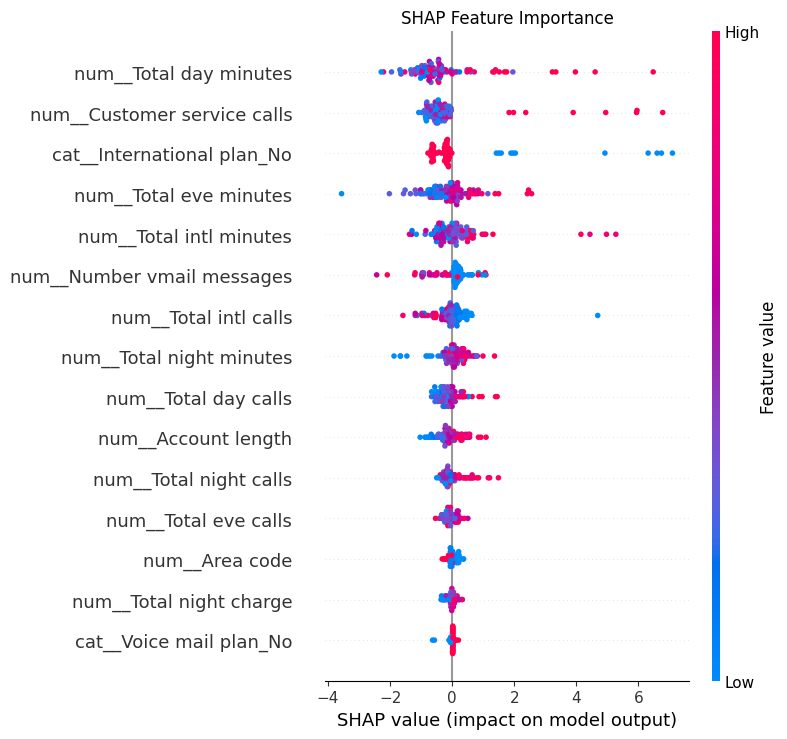

In [47]:
# ============================================================
# SHAP ANALYSIS
# ============================================================

try:

    # Select a manageable sample
    X_explain = X_test.sample(
        min(100, len(X_test)),
        random_state=42
    )

    # Extract preprocessing and model
    fitted_preprocessor = (
        best_model.named_steps["preprocessor"]
    )

    model_object = (
        best_model.named_steps["model"]
    )

    # Transform features
    X_transformed = (
        fitted_preprocessor.transform(
            X_explain
        )
    )

    # Feature names after encoding
    feature_names = (
        fitted_preprocessor
        .get_feature_names_out()
    )

    # Convert sparse matrix if necessary
    if hasattr(
        X_transformed,
        "toarray"
    ):
        X_transformed = (
            X_transformed.toarray()
        )

    # Tree-based models
    if isinstance(
        model_object,
        (
            RandomForestClassifier,
            HistGradientBoostingClassifier
        )
    ):

        explainer = shap.TreeExplainer(
            model_object
        )

        shap_values = explainer.shap_values(
            X_transformed
        )

        # Handle different SHAP output formats
        if isinstance(
            shap_values,
            list
        ):

            shap_values_plot = shap_values[-1]

        elif getattr(
            shap_values,
            "ndim",
            0
        ) == 3:

            shap_values_plot = (
                shap_values[:, :, -1]
            )

        else:

            shap_values_plot = shap_values

        plt.figure()

        shap.summary_plot(
            shap_values_plot,
            X_transformed,
            feature_names=feature_names,
            max_display=15,
            show=False
        )

        plt.title(
            "SHAP Feature Importance"
        )

        plt.tight_layout()
        plt.show()

    else:

        # Logistic Regression
        background = shap.sample(
            X_transformed,
            min(30, len(X_transformed)),
            random_state=42
        )

        explainer = shap.Explainer(
            model_object,
            background
        )

        shap_values = explainer(
            X_transformed[:50]
        )

        shap.plots.beeswarm(
            shap_values,
            max_display=15
        )

except Exception as error:

    print(
        "SHAP analysis could not be generated."
    )

    print(
        "Permutation importance is still available."
    )

    print(
        "Error:",
        str(error)[:500]
    )

In [48]:
# ============================================================
# FINAL MODEL RETRAINING
# ============================================================

# Combine training + validation data
X_train_final = pd.concat(
    [
        X_train,
        X_val
    ],
    axis=0
)

y_train_final = pd.concat(
    [
        y_train,
        y_val
    ],
    axis=0
)

print(
    "Final training data:",
    X_train_final.shape
)

# Retrain selected model
best_model.fit(
    X_train_final,
    y_train_final
)

print(
    "Final production model trained successfully!"
)

Final training data: (2833, 19)
Final production model trained successfully!


In [49]:
# ============================================================
# SAVE FINAL MODEL
# ============================================================

import joblib
import json

MODEL_FILE = (
    "telecommunication_customer_churn_model.joblib"
)

METADATA_FILE = (
    "telecommunication_customer_churn_metadata.json"
)

COMPARISON_FILE = (
    "model_comparison.csv"
)

IMPORTANCE_FILE = (
    "feature_importance.csv"
)

# Save model
joblib.dump(
    best_model,
    MODEL_FILE
)

# Save comparison
validation_results_df.to_csv(
    COMPARISON_FILE,
    index=False
)

# Save feature importance
importance_df.to_csv(
    IMPORTANCE_FILE,
    index=False
)

# Metadata
metadata = {

    "project_title":
        "Telecommunication Customer Churn Prediction Using Explainable Machine Learning",

    "target":
        TARGET,

    "selected_model":
        best_model_name,

    "test_accuracy":
        float(test_accuracy),

    "test_precision":
        float(test_precision),

    "test_recall":
        float(test_recall),

    "test_f1_score":
        float(test_f1),

    "test_roc_auc":
        float(test_roc_auc),

    "features":
        X.columns.tolist(),

    "positive_class":
        "1 = Churned",

    "negative_class":
        "0 = Stayed"
}

with open(
    METADATA_FILE,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        metadata,
        file,
        indent=4
    )

print("All project files saved successfully!")

print("\nModel:")
print(MODEL_FILE)

print("\nMetadata:")
print(METADATA_FILE)

print("\nModel comparison:")
print(COMPARISON_FILE)

print("\nFeature importance:")
print(IMPORTANCE_FILE)

All project files saved successfully!

Model:
telecommunication_customer_churn_model.joblib

Metadata:
telecommunication_customer_churn_metadata.json

Model comparison:
model_comparison.csv

Feature importance:
feature_importance.csv


In [50]:
# ============================================================
# GRADIO DEPLOYMENT
# ============================================================

!pip install -q gradio

In [51]:
# ============================================================
# GRADIO PREDICTION FUNCTION
# ============================================================

import gradio as gr

def predict_churn(*values):

    # Create one customer record
    input_data = pd.DataFrame(
        [
            dict(
                zip(
                    X.columns,
                    values
                )
            )
        ]
    )

    # Make sure feature order is correct
    input_data = input_data[
        X.columns
    ]

    # Prediction probability
    churn_probability = float(
        best_model.predict_proba(
            input_data
        )[0, 1]
    )

    # Classification
    prediction = int(
        churn_probability >= 0.50
    )

    if prediction == 1:

        result = "⚠️ HIGH CHURN RISK"

        recommendation = (
            "The customer has a high estimated "
            "churn probability. Recommended actions: "
            "proactive customer support, service-quality "
            "review, personalized offers, and retention "
            "campaigns."
        )

    else:

        result = "✅ LOW CHURN RISK"

        recommendation = (
            "The customer has a lower estimated "
            "churn probability. Continue customer "
            "engagement and monitor satisfaction."
        )

    return (
        result,
        f"{churn_probability:.2%}",
        recommendation
    )

In [52]:
# ============================================================
# CREATE GRADIO INPUT COMPONENTS
# ============================================================

inputs = []

for column in X.columns:

    # Categorical feature
    if column in categorical_features:

        choices = sorted(
            X[column]
            .dropna()
            .astype(str)
            .unique()
            .tolist()
        )

        component = gr.Dropdown(
            choices=choices,
            value=choices[0],
            label=column
        )

    # Numerical feature
    else:

        numeric_values = pd.to_numeric(
            X[column],
            errors="coerce"
        )

        median_value = numeric_values.median()

        component = gr.Number(
            value=float(median_value),
            label=column
        )

    inputs.append(component)

print(
    f"{len(inputs)} input fields created successfully!"
)

19 input fields created successfully!


In [53]:
# ============================================================
# LAUNCH PROFESSIONAL GRADIO APPLICATION
# ============================================================

demo = gr.Interface(

    fn=predict_churn,

    inputs=inputs,

    outputs=[
        gr.Textbox(
            label="Churn Prediction"
        ),

        gr.Textbox(
            label="Churn Probability"
        ),

        gr.Textbox(
            label="Retention Recommendation"
        )
    ],

    title=(
        "📊 Telecommunication Customer Churn "
        "Prediction Using Explainable Machine Learning"
    ),

    description=(
        "An explainable machine learning system "
        "for predicting telecommunication customer "
        "churn risk and supporting customer retention decisions."
    ),

    flagging_mode="never"
)

demo.launch(
    share=True
)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://ea7b9961a60e516be6.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
